In [1]:
import os
os.chdir("/Users/eloelo/Projects/plant-disease-detection")

import tensorflow as tf
from tensorflow import keras

print("TensorFlow:", tf.__version__)
print("Working from:", os.getcwd())

keras.utils.set_random_seed(42)

TensorFlow: 2.19.1
Working from: /Users/eloelo/Projects/plant-disease-detection


In [2]:
image_size = (224, 224)
batch_size = 32

train_data = tf.data.Dataset.load("data/splits_tfds/train")
val_data = tf.data.Dataset.load("data/splits_tfds/val")
test_data = tf.data.Dataset.load("data/splits_tfds/test")

def resize_image(image, label):
    image = tf.image.resize(image, image_size)
    return image, label

train_data = train_data.shuffle(14522, seed=42)

train_data = train_data.map(resize_image).batch(batch_size)
val_data = val_data.map(resize_image).batch(batch_size)
test_data = test_data.map(resize_image).batch(batch_size)

class_names = [
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___healthy",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Tomato___Target_Spot",
    "Tomato___Tomato_mosaic_virus",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
]

print("Train batches:", len(train_data))
print("Val batches:", len(val_data))
print("Test batches:", len(test_data))

Train batches: 454
Val batches: 57
Test batches: 58


2026-09-27 19:32:08.997636: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Pro
2026-09-27 19:32:08.997655: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-09-27 19:32:08.997662: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
I0000 00:00:1790517728.997673  123645 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1790517728.997689  123645 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [3]:
from tensorflow.keras import layers

normalization_layer = layers.Rescaling(1./255)

train_data = train_data.map(lambda x, y: (normalization_layer(x), y))
val_data = val_data.map(lambda x, y: (normalization_layer(x), y))
test_data = test_data.map(lambda x, y: (normalization_layer(x), y))

print("Pixel values now scaled to 0-1")

Pixel values now scaled to 0-1


In [4]:

baseline_cnn = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

baseline_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    23,888,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,908,682 (91.20 MB)

 Trainable params: 23,908,682 (91.20 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    min_delta=0.001,
    restore_best_weights=True,
)

lr_on_plateau = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.1,
    patience=3,
    min_lr=1e-7,
)

In [6]:
from tensorflow.keras.optimizers import Adam

baseline_cnn.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_history = baseline_cnn.fit(
    train_data,
    validation_data=val_data,
    epochs=30,
    callbacks=[early_stopping, lr_on_plateau],
)

Epoch 1/30


/opt/anaconda3/envs/plant/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-09-27 19:32:09.447967: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


454/454 ━━━━━━━━━━━━━━━━━━━━ 25s 51ms/step - accuracy: 0.6858 - loss: 0.9610 - val_accuracy: 0.8019 - val_loss: 0.5948 - learning_rate: 1.0000e-04
Epoch 2/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 25s 52ms/step - accuracy: 0.8365 - loss: 0.5040 - val_accuracy: 0.8477 - val_loss: 0.4840 - learning_rate: 1.0000e-04
Epoch 3/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 25s 52ms/step - accuracy: 0.8709 - loss: 0.3921 - val_accuracy: 0.8587 - val_loss: 0.4208 - learning_rate: 1.0000e-04
Epoch 4/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 24s 50ms/step - accuracy: 0.8936 - loss: 0.3205 - val_accuracy: 0.8526 - val_loss: 0.4634 - learning_rate: 1.0000e-04
Epoch 5/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 24s 50ms/step - accuracy: 0.9037 - loss: 0.2892 - val_accuracy: 0.8996 - val_loss: 0.3226 - learning_rate: 1.0000e-04
Epoch 6/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 24s 50ms/step - accuracy: 0.9148 - loss: 0.2538 - val_accuracy: 0.8764 - val_loss: 0.3932 - learning_rate: 1.0000e-04
Epoch 7/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 24s 50ms/step - accurac

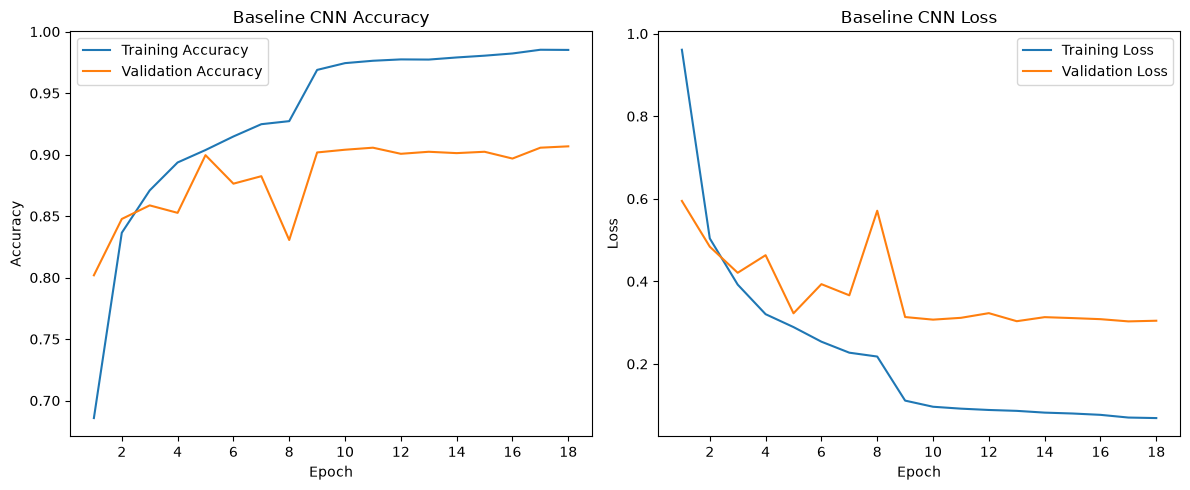

In [9]:
import matplotlib.pyplot as plt

epochs_range = list(range(1, len(baseline_history.history["loss"]) + 1))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, baseline_history.history["accuracy"], label="Training Accuracy")
plt.plot(epochs_range, baseline_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Baseline CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.xticks(range(2, len(epochs_range) + 1, 2))

plt.subplot(1, 2, 2)
plt.plot(epochs_range, baseline_history.history["loss"], label="Training Loss")
plt.plot(epochs_range, baseline_history.history["val_loss"], label="Validation Loss")
plt.title("Baseline CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.xticks(range(2, len(epochs_range) + 1, 2))

plt.tight_layout()
plt.savefig("reports/figures/baseline_curves.png", dpi=150)
plt.show()

### Baseline CNN
- Simple CNN from scratch: 2 conv layers, then Flatten and Dense, 23.9M params (most in the Dense layer)
- Kept deliberately plain, with no augmentation and no dropout, so it works as the reference point for the transfer learning models
- Settings: image 224 x 224, batch size 32, Adam, max 30 epochs, seed 42
- LR 0.0001: tried the default 0.001 first and val loss exploded above 300
- Batch size and optimizer kept fixed (32, Adam), and only the LR was tuned
- EarlyStopping (patience 5) and ReduceLROnPlateau (patience 3), both on val loss
- LR dropped at epoch 9 (1e-4 to 1e-5), and val acc went from 83% to 90%
- Stopped at epoch 18, best weights restored from epoch 13 (checked in the cell below: val loss 0.3035, val acc 0.9023)
- Best val acc 90.2%, val loss 0.30
- Train acc 97.7%, so a 7.5 point gap: clearly overfitting
- Test results and error analysis are in notebook 04

In [11]:
print(baseline_cnn.evaluate(val_data))

57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9023 - loss: 0.3035
[0.30347272753715515, 0.9023178815841675]


In [12]:
baseline_cnn.save("models/baseline_cnn.keras")
print("Model saved")

Model saved
